In [1]:
import pandas as pd  # For data manipulation
import numpy as np   # For numerical operations
import matplotlib.pyplot as plt  # For plotting
import seaborn as sns  # For advanced visualizations
import matplotlib.dates as mdates
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import GridSearchCV
sns.set(style="whitegrid")

In [2]:
file_path = 'Walmart_Sales.csv' 
data = pd.read_csv(file_path)

data.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [4]:
data.tail()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667
6434,45,26-10-2012,760281.43,0,58.85,3.882,192.308899,8.667


In [5]:
data.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


In [6]:
data.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

In [7]:
unique_counts = data.apply(pd.Series.nunique)
print(unique_counts)

Store             45
Date             143
Weekly_Sales    6435
Holiday_Flag       2
Temperature     3528
Fuel_Price       892
CPI             2145
Unemployment     349
dtype: int64


In [8]:
data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y', errors='coerce')

# Extract additional time features
data['Year'] = data['Date'].dt.year
data['Month'] = data['Date'].dt.month
data['Week'] = data['Date'].dt.isocalendar().week


data.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Week
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,2010,2,5
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2010,2,6
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2010,2,7
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2010,2,8
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,2010,3,9


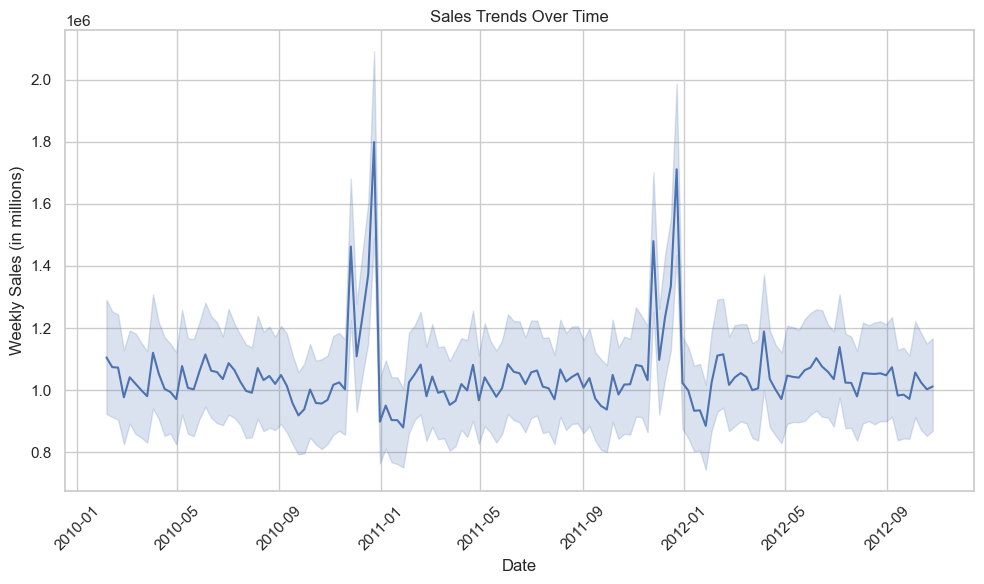

In [9]:
plt.figure(figsize=(10,6))
sns.lineplot(x='Date', y='Weekly_Sales', data=data)



plt.xticks(rotation=45)

plt.title('Sales Trends Over Time')
plt.xlabel('Date')
plt.ylabel('Weekly Sales (in millions)')

plt.tight_layout()
plt.show()

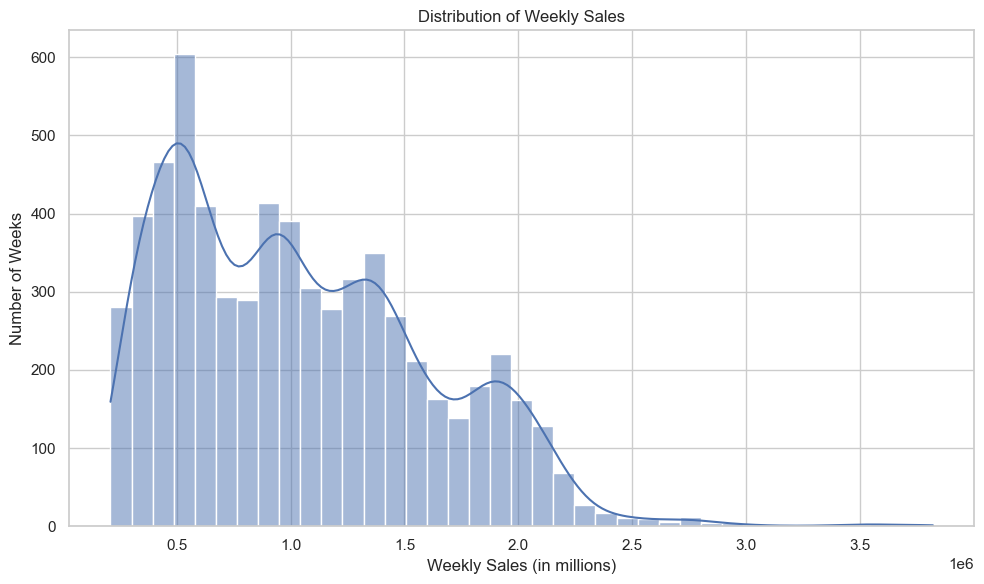

In [10]:
plt.figure(figsize=(10,6))
sns.histplot(data['Weekly_Sales'], kde=True)

# Add title and labels
plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales (in millions)')  # Adjusted for clarity
plt.ylabel('Number of Weeks')

# Show the plot
plt.tight_layout()
plt.show()

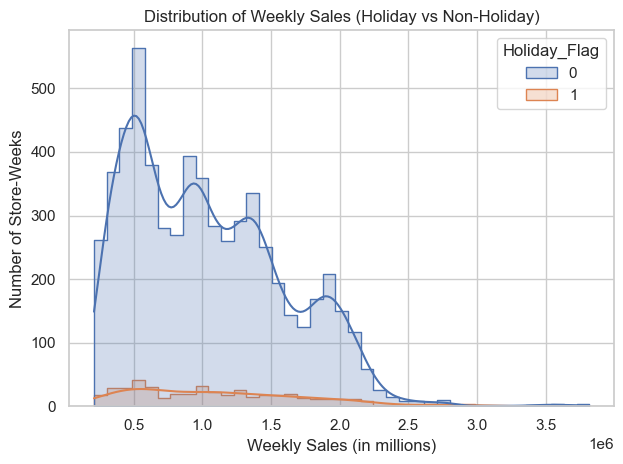

In [11]:
sns.histplot(data=data, x='Weekly_Sales', kde=True, hue='Holiday_Flag', element='step')
plt.title('Distribution of Weekly Sales (Holiday vs Non-Holiday)')
plt.xlabel('Weekly Sales (in millions)')
plt.ylabel('Number of Store-Weeks')
plt.tight_layout()
plt.show()

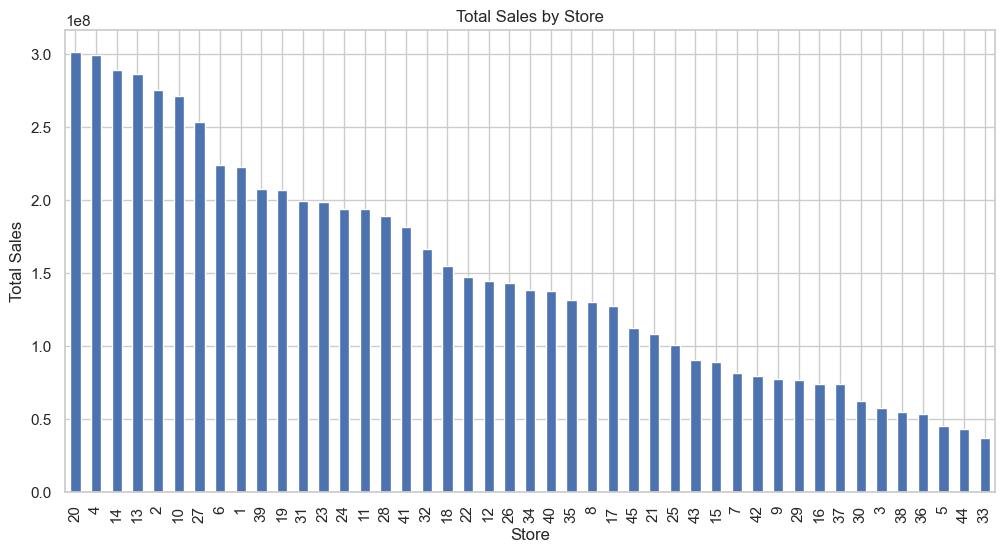

In [12]:
# Group by Store to analyze performance
store_sales = data.groupby('Store')['Weekly_Sales'].sum().sort_values(ascending=False)
store_sales.plot(kind='bar', figsize=(12, 6))
plt.title('Total Sales by Store')
plt.xlabel('Store')
plt.ylabel('Total Sales')
plt.show()

Observation: Stores 20, 4, and 14 are the top 3 performing stores, while Stores 33, 5, and 36 are among the lowest in terms of total sales.

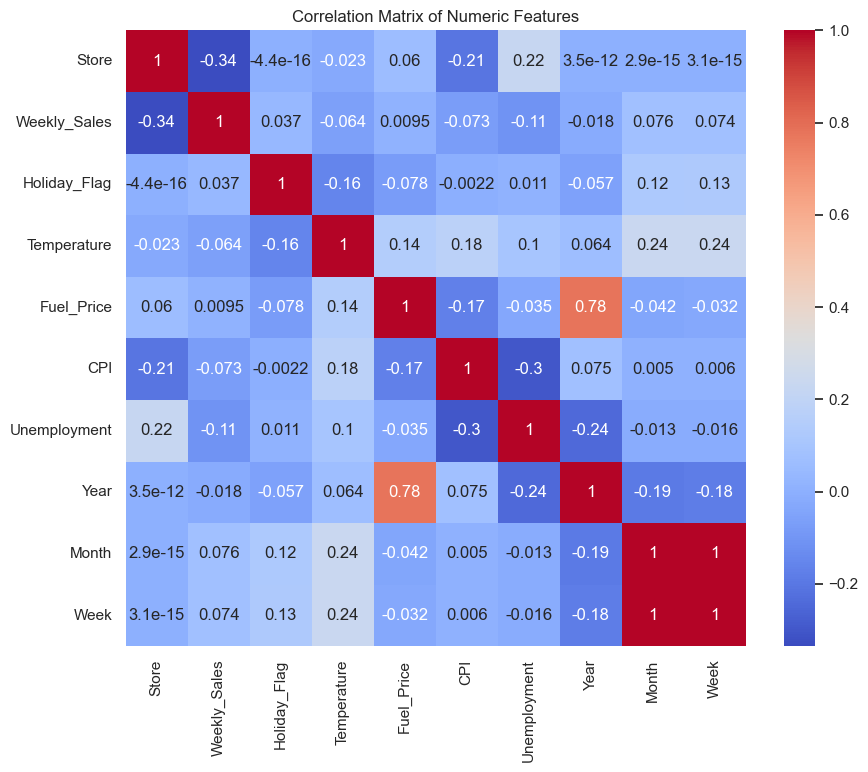

In [13]:
numeric_data = data.select_dtypes(include=[np.number])  # Select only numeric columns

# Create the correlation matrix with only numeric columns
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix of Numeric Features')
plt.show()

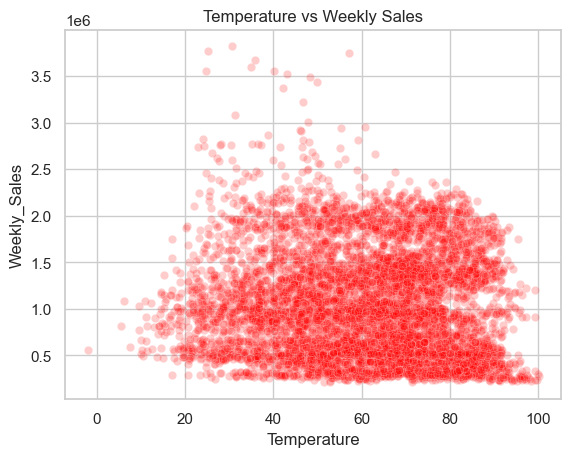

In [14]:
sns.scatterplot(x='Temperature', y='Weekly_Sales', alpha = 0.2, color = 'red', data=data)
plt.title('Temperature vs Weekly Sales')
plt.show()

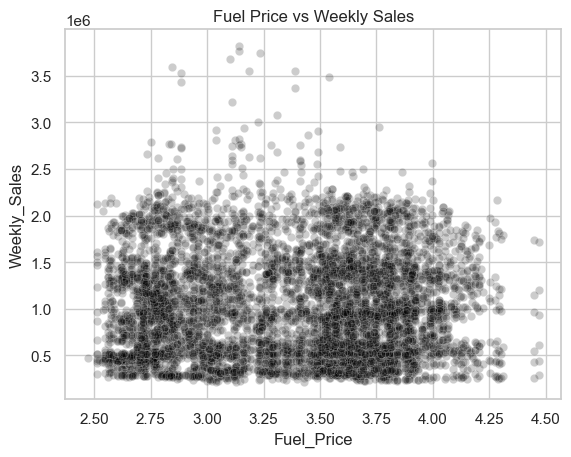

In [15]:
sns.scatterplot(x='Fuel_Price', y='Weekly_Sales',alpha = 0.2, color = "black" ,data=data)
plt.title('Fuel Price vs Weekly Sales')
plt.show()

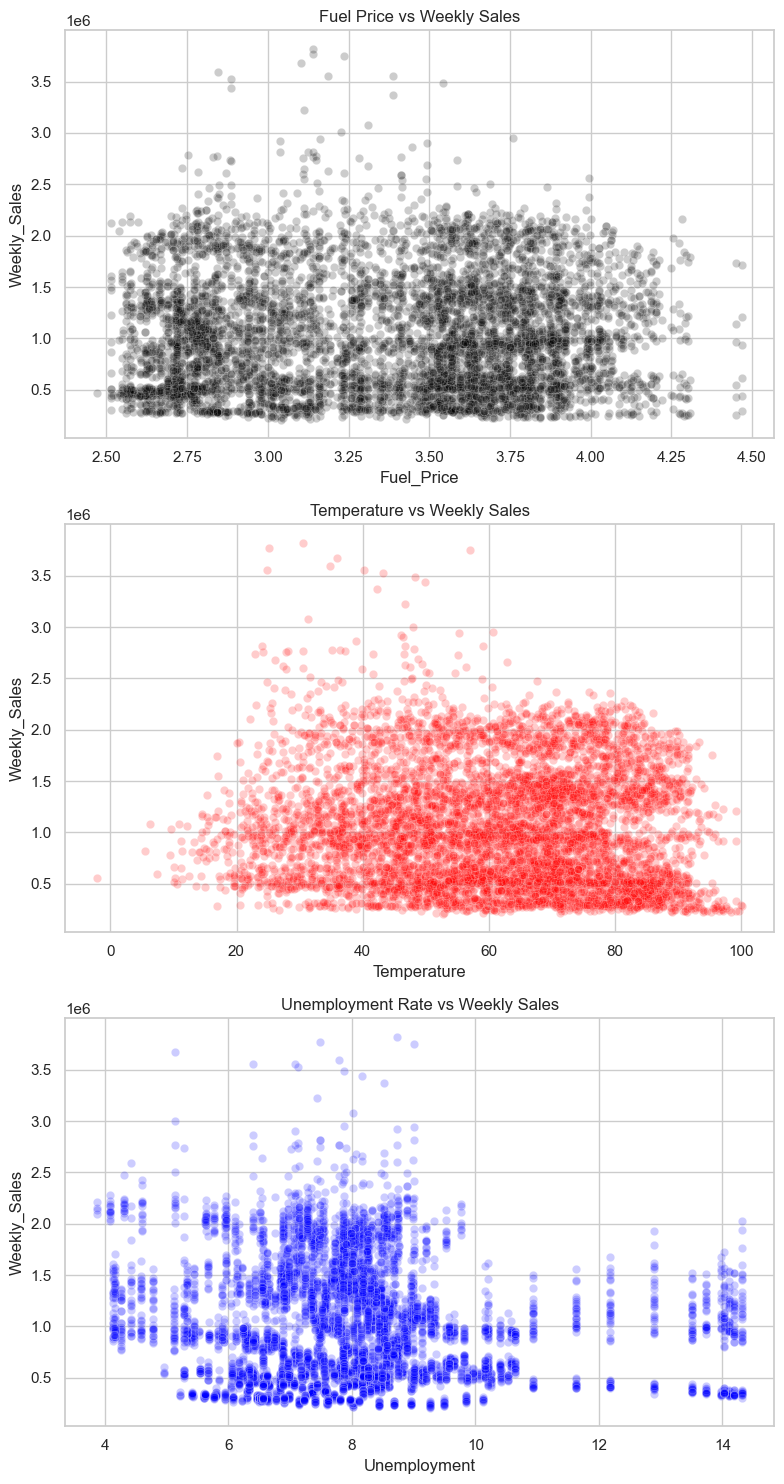

In [16]:
# scatter plots 
fig, axes = plt.subplots(3, 1, figsize=(8, 15))  # 3 riviä ja 1 sarake

# Plot 1: Fuel Price vs Weekly Sales
sns.scatterplot(x='Fuel_Price', y='Weekly_Sales', alpha=0.2, color='black', data=data, ax=axes[0])
axes[0].set_title('Fuel Price vs Weekly Sales')

# Plot 2: Temperature vs Weekly Sales
sns.scatterplot(x='Temperature', y='Weekly_Sales', alpha=0.2, color='red', data=data, ax=axes[1])
axes[1].set_title('Temperature vs Weekly Sales')

# Plot 3: Unemployment Rate vs Weekly Sales
sns.scatterplot(x='Unemployment', y='Weekly_Sales', alpha=0.2, color='blue', data=data, ax=axes[2])
axes[2].set_title('Unemployment Rate vs Weekly Sales')

plt.tight_layout()
plt.show()


Next, t-test to check if  is a statistically significant difference in weekly sales between holiday and non-holiday weeks.We are using a 5% significance level, which means that we will reject the null hypothesis if the p-value is less than 0.05

In [17]:
from scipy.stats import ttest_ind

# Split sales data into holiday and non-holiday weeks
holiday_sales = data[data['Holiday_Flag'] == 1]['Weekly_Sales']
non_holiday_sales = data[data['Holiday_Flag'] == 0]['Weekly_Sales']

# Perform t-test
t_stat, p_val = ttest_ind(holiday_sales, non_holiday_sales)
print(f"T-statistic: {t_stat}, P-value: {p_val}")

T-statistic: 2.9608919093259036, P-value: 0.003078699263818616


The p-value indicates a statistically significant difference between holiday and non-holiday

<Axes: ylabel='Weekly_Sales'>

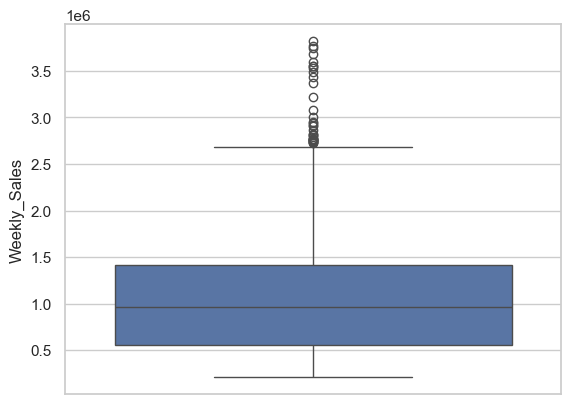

In [18]:
#checking for outliers

sns.boxplot(data['Weekly_Sales'])

In [19]:
#Possible outliers, so lets clean them

Q1 = data['Weekly_Sales'].quantile(0.25)
Q3 = data['Weekly_Sales'].quantile(0.75)

IQR = Q3 - Q1

lb = Q1-1.5*IQR
ub = Q3 + 1.5*IQR

outliers= data[(data["Weekly_Sales"] < lb) | (data["Weekly_Sales"] > ub)].index# outlier value



In [20]:
clean_data = data.drop(outliers, axis = 0)
clean_data.shape

(6401, 11)

 Adding lag variables (e.g., Sales_Lag1, Sales_Lag2) to account for the sales trend in the previous weeks.

In [21]:
clean_data['Sales_Lag1'] = clean_data['Weekly_Sales'].shift(1)
clean_data['Sales_Lag2'] = clean_data['Weekly_Sales'].shift(2)
clean_data = clean_data.dropna()


In [22]:
clean_data[['Holiday_Flag']] = clean_data[['Holiday_Flag']].astype(str)  # Muunna merkkijonoksi
clean_data = pd.get_dummies(clean_data, columns=['Holiday_Flag'], drop_first=True)


In [23]:
# Laske 4 viikon liukuva keskiarvo
clean_data['Rolling_Mean_4'] = clean_data['Weekly_Sales'].rolling(window=4).mean()

# Poista kaikki rivit, joissa on NaN-arvoja (esim. ensimmäiset kolme riviä liukuvan keskiarvon vuoksi)
clean_data.dropna(subset=['Rolling_Mean_4'], inplace=True)



In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Define the features and target variable
X = clean_data[['Store','Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Holiday_Flag_1']]
y = clean_data['Weekly_Sales']


In [25]:
# Jaa data koulutus- ja testijoukkoihin
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [26]:


#Random forwest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

#train the model
rf_model.fit(X_train, y_train)


RandomForestRegressor(random_state=42)

In [27]:
from sklearn.metrics import mean_squared_error, r2_score

# Tee ennusteet testidatalla
y_pred = rf_model.predict(X_test)

# Laske MSE ja R²
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse}")
print(f"R-squared (R²): {r2}")


Mean Squared Error (MSE): 17952520360.302795
R-squared (R²): 0.9417077503513916


Hyperparameter optimatization 


In [28]:
# Määrittele parametriverkko
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

# Aseta GridSearchCV
grid_search = GridSearchCV(estimator=rf_model, param_grid=param_grid, cv=3, n_jobs=-1, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

# Tulosta parhaat parametrit
print("Best Parameters:", grid_search.best_params_)


Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 300}


In [29]:


# Hae parhaat parametrit GridSearchCV:stä
best_params = grid_search.best_params_

# Luo uusi Random Forest -malli käyttämällä optimoituja parametreja
best_rf_model = RandomForestRegressor(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    min_samples_split=best_params['min_samples_split'],
    random_state=42
)

# Kouluta uusi malli käyttäen optimoituja hyperparametreja
best_rf_model.fit(X_train, y_train)

# Tee ennusteet testidatalla
y_pred = best_rf_model.predict(X_test)

# Arvioi mallin suorituskyky
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Tulosta tulokset
print(f"Optimized Random Forest - Mean Squared Error (MSE): {mse}")
print(f"Optimized Random Forest - R²: {r2}")


Optimized Random Forest - Mean Squared Error (MSE): 17799467216.51012
Optimized Random Forest - R²: 0.9422047174561997


In [30]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Tarkistetaan VIF kaikille ominaisuuksille
X = clean_data[['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Holiday_Flag_1', 'Sales_Lag1','Store']]
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

print(vif_data)


          feature        VIF
0     Temperature  13.434575
1      Fuel_Price  30.154581
2             CPI  14.864253
3    Unemployment  16.489765
4  Holiday_Flag_1   1.104287
5      Sales_Lag1   4.846666
6           Store   4.847323


In [31]:
from sklearn.model_selection import cross_val_score

# Suorita ristiinvalidointi
cv_scores = cross_val_score(best_rf_model, X_train, y_train, cv=5, scoring='r2')

# Tulosta keskimääräinen R² ristiinvalidoinnissa
print(f"Cross-validated R²: {cv_scores.mean()}")


Cross-validated R²: 0.9463612712482952


In [32]:
feature_importance = best_rf_model.feature_importances_
sns.barplot(x=feature_importance, y=X.columns)
plt.title('Feature Importance')
plt.show()

ValueError: All arrays must be of the same length

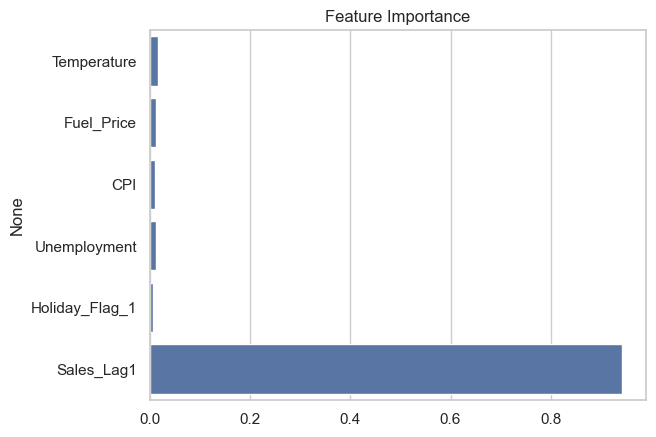

In [32]:
feature_importance = rf_model.feature_importances_
sns.barplot(x=feature_importance, y=X.columns)
plt.title('Feature Importance')
plt.show()

In [33]:
# Ennusteet testidatalla
y_pred_test = best_rf_model.predict(X_test)

# performance with test data
test_mse = mean_squared_error(y_test, y_pred_test)
test_r2 = r2_score(y_test, y_pred_test)

print(f"Test Mean Squared Error (MSE): {test_mse}")
print(f"Test R²: {test_r2}")


Test Mean Squared Error (MSE): 24457225297.359882
Test R²: 0.9205868226781994


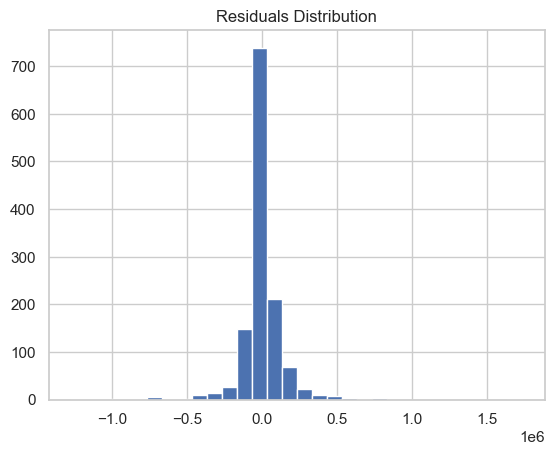

In [34]:
import matplotlib.pyplot as plt

# Laske residuaalit testidatalla
residuals = y_test - y_pred_test

# Piirrä residuaalien jakauma
plt.hist(residuals, bins=30)
plt.title('Residuals Distribution')
plt.show()


In [35]:
# Ennusta testidatalla
y_pred = rf_model.predict(X_test)

# Tarkista ennustetut myyntiarvot
print(y_pred)


[ 838881.4958  641445.6556 1612115.797  ... 1697989.3    1084870.4757
 1383364.684 ]


In [36]:
# Lasketaan ennustusten tarkkuus
from sklearn.metrics import mean_squared_error, r2_score

# Vertaa ennusteita todellisiin myyntiarvoihin (y_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse}")
print(f"R-squared (R²): {r2}")
print(np.sqrt(mse))

Mean Squared Error (MSE): 25190641494.534218
R-squared (R²): 0.9182054032895014
158715.59940514422


In [37]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Oletetaan, että testidata on valmis
# Step 1: Laske Weekly_Sales-keskiarvo ja keskihajonta
mean_sales = y_test.mean()

print(f"Mean Weekly Sales: {mean_sales}")

# Step 2: Luodaan baseline-malli, joka ennustaa keskiarvon kaikille arvoille
baseline_predictions = np.full_like(y_test, mean_sales)

# Step 3: Laske baseline-mallin suorituskyky (RMSE, MAE, R-squared)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_r2 = r2_score(y_test, baseline_predictions)

print(f"Baseline RMSE: {baseline_rmse}")
print(f"Baseline MAE: {baseline_mae}")
print(f"Baseline R-Squared: {baseline_r2}")


Mean Weekly Sales: 1041531.2269765625
Baseline RMSE: 554954.4086799972
Baseline MAE: 469686.334996167
Baseline R-Squared: 0.0


In [73]:
sarima_data = clean_data.copy()

sarima_data['Date'] = pd.to_datetime(sarima_data['Date'])

aggregated_data = sarima_data.groupby('Date')['Weekly_Sales'].sum().reset_index()




XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <B9202094-7D52-318C-99CF-7034B0E9F28D> /Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/O